In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [4]:
img = cv2.imread("sample_image.jpg", cv2.IMREAD_GRAYSCALE)

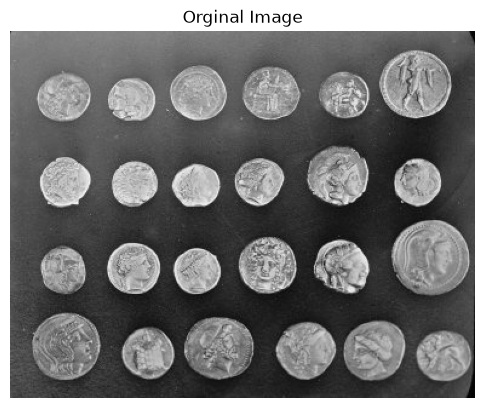

In [6]:
plt.figure(figsize=(6, 5))
plt.imshow(img, cmap="gray")
plt.title("Orginal Image")
plt.axis("off")
plt.show()

In [41]:
fixed_threshold = 127

In [42]:
global_thresh_manual = np.where(img >= fixed_threshold, 255, 0)
global_thresh_manual = global_thresh_manual.astype(np.uint8)

In [43]:
_, global_thresh_cv2 = cv2.threshold(img, fixed_threshold, 255, cv2.THRESH_BINARY)

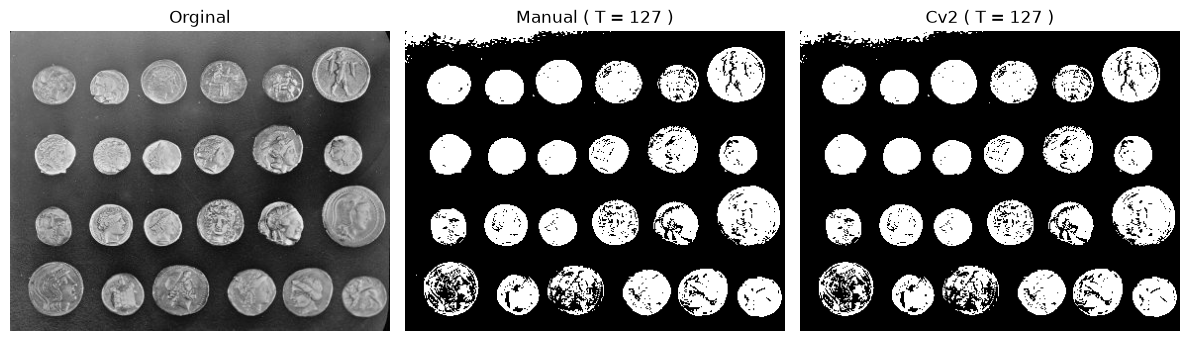

In [44]:
plt.figure(figsize=(12, 10))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Orginal")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(global_thresh_manual, cmap="gray")
plt.title(f"Manual ( T = {fixed_threshold} )")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(global_thresh_cv2, cmap="gray")
plt.title(f"Cv2 ( T = {fixed_threshold} )")
plt.axis("off")

plt.tight_layout()

# Otsu method

In [35]:
otsu_value, otsu_thresh = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

In [36]:
print("\nOtsu automatically selected threshold value : ", otsu_value)


Otsu automatically selected threshold value :  107.0


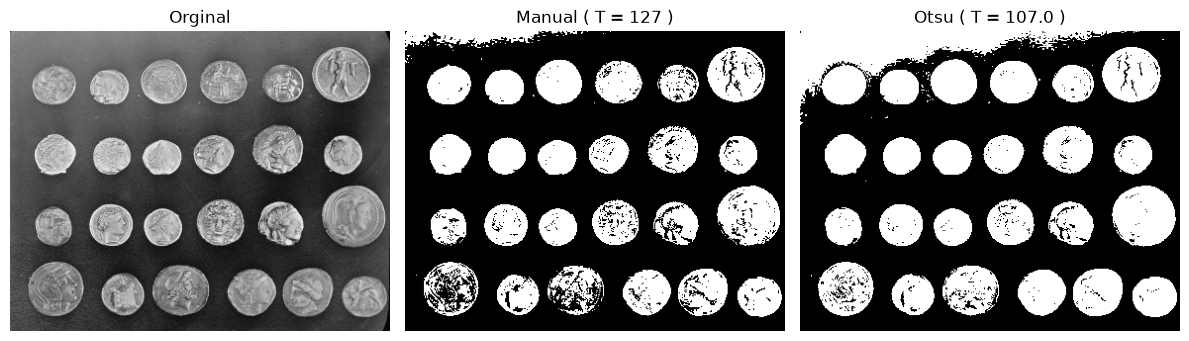

In [46]:
plt.figure(figsize=(12, 10))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Orginal")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(global_thresh_manual, cmap="gray")
plt.title(f"Manual ( T = {fixed_threshold} )")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(otsu_thresh, cmap="gray")
plt.title(f"Otsu ( T = {otsu_value} )")
plt.axis("off")

plt.tight_layout()

Text(0.5, 1.0, 'Histogram with Otsu Threshhold')

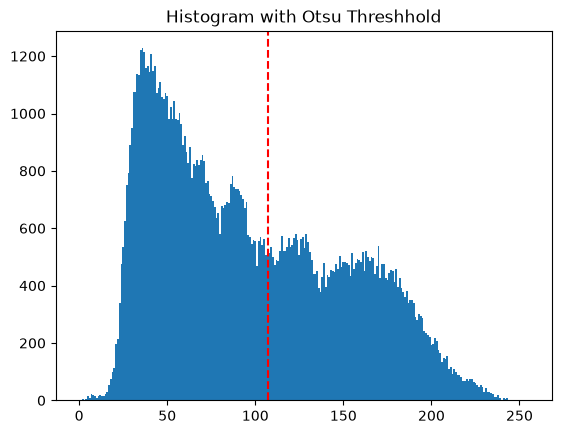

In [48]:
hist, _ = np.histogram(img, 256, (0, 256))

plt.bar(range(0,256), hist, 1)
plt.axvline( x=otsu_value, color="red", linestyle="--", label=f"Otsu thrshold = {otsu_value}")
plt.title("Histogram with Otsu Threshhold")

In [50]:
adaptive_mean = cv2.adaptiveThreshold(
    img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY,
    blockSize=11, C=2
)

In [51]:
adaptive_gaussian = cv2.adaptiveThreshold(
    img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
    blockSize=11, C=2
)

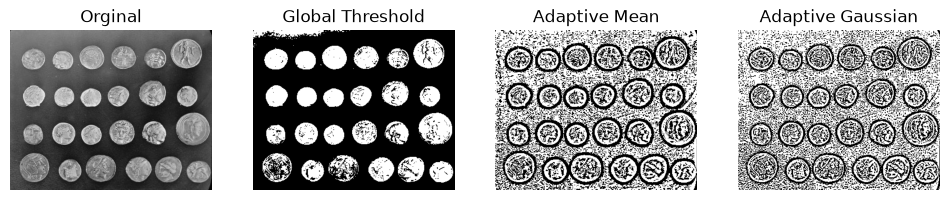

In [56]:
plt.figure(figsize=(12, 10))

plt.subplot(1,4,1)
plt.imshow(img, cmap="gray")
plt.title("Orginal")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(global_thresh_cv2, cmap="gray")
plt.title("Global Threshold")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(adaptive_mean, cmap="gray")
plt.title("Adaptive Mean")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(adaptive_gaussian, cmap="gray")
plt.title("Adaptive Gaussian")
plt.axis("off")

plt.show()

In [57]:
extracted_region = cv2.bitwise_and(img, img, mask=otsu_thresh)

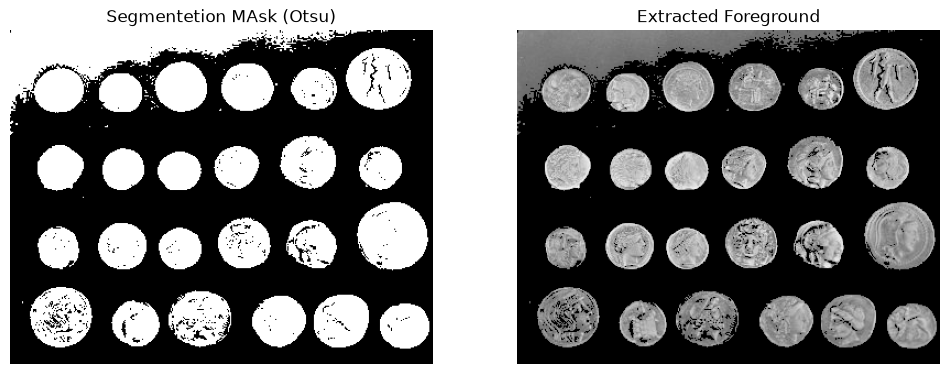

In [58]:
plt.figure(figsize=(12, 10))

plt.subplot(1,2,1)
plt.imshow(otsu_thresh, cmap="gray")
plt.title("Segmentetion MAsk (Otsu)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(extracted_region, cmap="gray")
plt.title("Extracted Foreground")
plt.axis("off")

plt.show()

In [61]:
canny_edges = cv2.Canny(img, 100, 200)

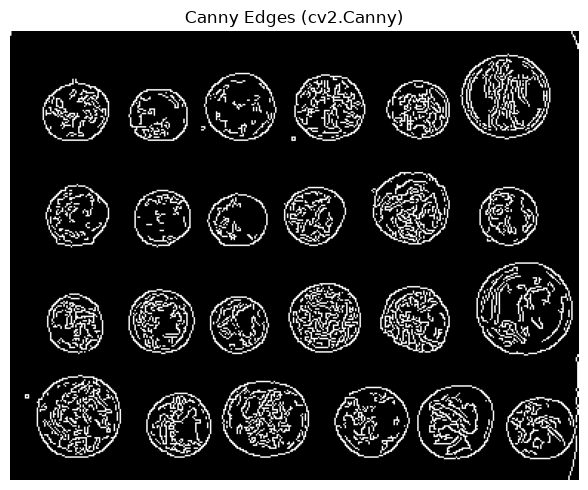

In [62]:
plt.figure(figsize=(10,5))
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny Edges (cv2.Canny)")
plt.axis("off")
plt.tight_layout()
plt.show()

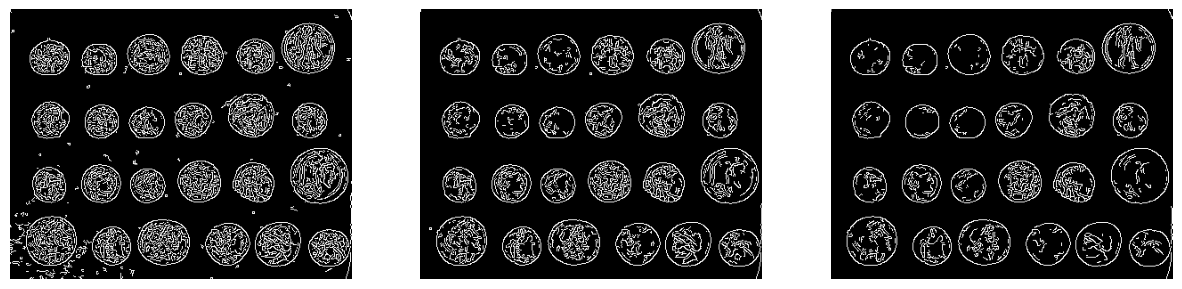

In [64]:
threshold_pairs = [(50, 100), (100,200), (150,250)]
plt.figure(figsize=(15,4))
for i, (t1,t2) in enumerate(threshold_pairs):
    edges = cv2.Canny(img, t1, t2)
    plt.subplot(1, len(threshold_pairs), i + 1)
    plt.imshow(edges, cmap="gray")
    plt.axis("off")
plt.show()

In [65]:
_ , binary = cv2.threshold(img,0,255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

In [66]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary)

In [68]:
print("Number of connected componets found (including background) : ", num_labels)
print("Number of actual objects (excluding background) : ", num_labels - 1)

Number of connected componets found (including background) :  95
Number of actual objects (excluding background) :  94


In [69]:
colored_labls = np.zeros((*labels.shape, 3), dtype = np.uint8)
rng = np.random.default_rng(42)
colors = rng.integers(0, 255, size=(num_labels, 3))
colors[0] = [0,0,0]

In [70]:
for label_id in range(num_labels):
    colored_labels[labels == label_id] = colors[label_id]

NameError: name 'colored_labels' is not defined